In [3]:
!pip install pandas numpy matplotlib

In [4]:
import os, re, sys, json, csv, gzip, string
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
file_path = "/content/drive/MyDrive/CAISI_phase2/safe-finetuning/SaLoRA/outputs/debug_run/checkpoint-1330/trainer_state.json"

In [6]:
trainer_state_data = []
with open(file_path, 'r') as file:
  data = json.load(file) #Open JSON file and loads it into a dictionary

#looks like:
#{
#  "best_model_checkpoint": "checkpoint-1330",
# "log_history": [
#   {"loss": 1.234, "learning_rate": 1e-5, "step": 10},
#   {"loss": 1.123, "learning_rate": 1e-5, "step": 20},
#   {"eval_loss": 1.045, "eval_accuracy": 0.82, "step": 30}
# ],
# "epoch": 3.0,
#  ...
#}

df = pd.json_normalize(data, record_path=['log_history']) #Pandas function that flattens dictionary into a dataframe;
#makes each dictionary in the list at the key log_history a row in the dataframe

In [7]:
df

,entropy,epoch,grad_norm,learning_rate,loss,mean_token_accuracy,num_tokens,step,eval_entropy,eval_loss,eval_mean_token_accuracy,eval_num_tokens,eval_runtime,eval_samples_per_second,eval_steps_per_second
0,2.843292,0.003759,13.812164,0.000000e+00,2.0884,0.517296,3559.0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2.912617,0.037594,11.114123,2.686567e-05,2.1628,0.508301,31228.0,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2.152202,0.075188,5.172943,5.671642e-05,1.7834,0.560792,65225.0,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1.798347,0.112782,1.889546,8.656716e-05,1.5180,0.602559,94375.0,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1.581392,0.150376,1.210930,1.164179e-04,1.3012,0.642807,123871.0,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
134,1.291928,4.887218,0.458608,4.908947e-06,0.9750,0.706856,4005559.0,1300,NaN,NaN,NaN,NaN,NaN,NaN,NaN
135,1.261266,4.924812,0.416743,3.325416e-06,0.9196,0.722691,4036982.0,1310,NaN,NaN,NaN,NaN,NaN,NaN,NaN
136,1.288942,4.962406,0.495212,1.741884e-06,0.9516,0.710229,4067948.0,1320,NaN,NaN,NaN,NaN,NaN,NaN,NaN
137,1.330329,5.000000,0.637220,1.583531e-07,0.9738,0.710498,4096470.0,1330,NaN,NaN,NaN,NaN,NaN,NaN,NaN


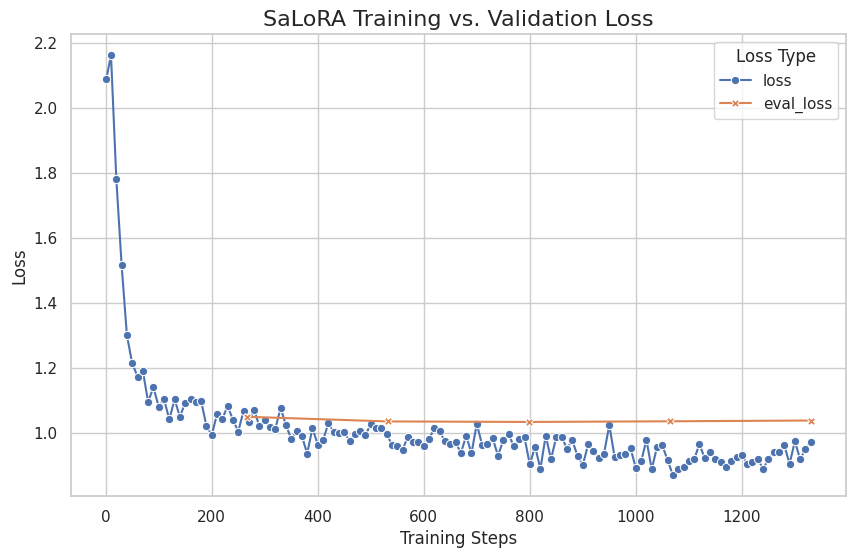

In [9]:
  log_history = pd.DataFrame(data.get("log_history", []))
  log_history = log_history[(log_history["loss"].notna()) | (log_history["eval_loss"].notna())]

  df_melted = log_history.melt(
      id_vars=["step"],
      value_vars=["loss", "eval_loss"],
      var_name="Loss Type",
      value_name="Loss"
  )

#Plot loss vs. steps

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10,6))
sns.lineplot(
    data=df_melted,
    x="step", y="Loss", hue="Loss Type",
    style="Loss Type", markers=True, dashes=False
)
plt.xlabel("Training Steps", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.title("SaLoRA Training vs. Validation Loss", fontsize=16)
plt.legend(title="Loss Type")
plt.show()